#### This file contains dataset loading, cleaning it, understanding it and visulaizing it and using dataset to train our ml models.

## Installing libraries:

In [30]:
%pip install pandas
%pip install numpy
%pip install scikit-learn
%pip install matplotlib
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Importing files and libraries:

In [31]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt

## Loading dataset:

In [32]:
df = pd.read_csv(r'/home/abhinav/Desktop/Aquagaurd_Project/Datasets/Ground Water 2021.csv')

## Adding several data:

In [33]:
np.random.seed(42)
df["BOD"] = np.random.uniform(1.0, 5.0, len(df)) #Biochemical Oxygen Demand.
#DO depends on BOD.
df["DO"] = 9 - (0.8*df['BOD']) + np.random.normal(0,0.15,len(df))
conductivity = (df["Conductivity (µmhos/cm) Min"] + df["Conductivity (µmhos/cm) Max"]) / 2
df["Nitrate"] = (conductivity/100) + np.random.normal(2,0.8,len(df))
df["Fluoride"] = np.random.uniform(0.4, 1.5, len(df)) #Natural floride.

## Understanding dataset:

In [34]:
print(df.info())
print(df.describe())
print(df.shape)
print(df.columns)

<class 'pandas.DataFrame'>
RangeIndex: 988 entries, 0 to 987
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Station Code                 980 non-null    float64
 1   Station Name                 988 non-null    str    
 2   STATE                        980 non-null    str    
 3   Temperature Min              980 non-null    float64
 4   Temperature Max              980 non-null    float64
 5   pH Min                       980 non-null    float64
 6   pH Max                       980 non-null    float64
 7   Conductivity (µmhos/cm) Min  979 non-null    float64
 8   Conductivity (µmhos/cm) Max  979 non-null    float64
 9   Year                         988 non-null    int64  
 10  BOD                          988 non-null    float64
 11  DO                           988 non-null    float64
 12  Nitrate                      979 non-null    float64
 13  Fluoride                     98

## Dataset Overview:

The dataset contains 988 groundwater quality records from monitoring stations across India for the year 2021. It includes 10 features such as station details, temperature, pH, conductivity, and year. A few missing values are present, and the dataset will be cleaned before performing visualization and machine learning analysis.

## Exploratory data analysis and Cleaning Data:

### Step 1 : Finding and resloving null values.

In [35]:
print(df.isnull().sum())
# Delintig null rows from state and station code as it can create wrong or inconsitant data.
df = df.dropna(subset=['Station Code'])
df = df.dropna(subset=['STATE'])
#Filling nulls in temprature columns with medians for better values.
df['Temperature Max'] = df['Temperature Max'].fillna(df['Temperature Max'].median())
df['Temperature Min'] = df['Temperature Min'].fillna(df['Temperature Min'].median())
#State wise pH values differ so we fill it likewise.
df['pH Min'] = df.groupby('STATE')['pH Min'].transform(lambda x:x.fillna(x.mean()))
df['pH Max'] = df.groupby('STATE')['pH Max'].transform(lambda x:x.fillna(x.mean()))
#Same for Conductivity column.
df['Conductivity (µmhos/cm) Min'] = df.groupby('STATE')['Conductivity (µmhos/cm) Min'].transform(lambda x:x.fillna(x.median()))
df['Conductivity (µmhos/cm) Max'] = df.groupby('STATE')['Conductivity (µmhos/cm) Max'].transform(lambda x:x.fillna(x.median()))
#Check again for nulls.
print(df.isnull().sum())
print(df[df["Nitrate"].isnull()])
df["Nitrate"] = df["Nitrate"].fillna(df["Nitrate"].mean())
print(df.isna().sum())

Station Code                   8
Station Name                   0
STATE                          8
Temperature Min                8
Temperature Max                8
pH Min                         8
pH Max                         8
Conductivity (µmhos/cm) Min    9
Conductivity (µmhos/cm) Max    9
Year                           0
BOD                            0
DO                             0
Nitrate                        9
Fluoride                       0
dtype: int64
Station Code                   0
Station Name                   0
STATE                          0
Temperature Min                0
Temperature Max                0
pH Min                         0
pH Max                         0
Conductivity (µmhos/cm) Min    0
Conductivity (µmhos/cm) Max    0
Year                           0
BOD                            0
DO                             0
Nitrate                        1
Fluoride                       0
dtype: int64
     Station Code                                 

### Step 2 : Finding and Dropping duplicates.

In [36]:
print(df.duplicated().sum())
df = df.drop_duplicates()

0


### The columns are already in proper datatype like numerical like Stateion code in int, pH values in float and categorical in str.

In [37]:
#Check using below.
#df.info()

### Step 3 : Validating Dataset Consistency:

In [38]:
#Checking for columns where there should only be one unique value for certain attribute. 
print(df['Year'].unique())
print(df['STATE'].unique())
print(df['Station Name'].unique())
#This enusures encoding will be done with proper values.

[2021]
<StringArray>
[      'ANDHRA PRADESH',                'ASSAM',                'BIHAR',
           'CHANDIGARH',         'CHHATTISGARH',          'DAMAN & DIU',
 'DADRA & NAGAR HAVELI',                  'GOA',              'GUJARAT',
              'HARYANA',     'HIMACHAL PRADESH',      'JAMMU & KASHMIR',
            'JHARKHAND',            'KARNATAKA',               'KERALA',
          'LAKSHADWEEP',       'MADHYA PRADESH',          'MAHARASHTRA',
              'MANIPUR',            'MEGHALAYA',              'MIZORAM',
             'NAGALAND',               'ODISHA',           'PUDUCHERRY',
               'PUNJAB',            'RAJASTHAN',           'TAMIL NADU',
            'TELANGANA',              'TRIPURA',        'UTTAR PRADESH',
          'UTTARAKHAND',          'WEST BENGAL']
Length: 32, dtype: str
<StringArray>
[                                    'BORE WELL AT ALLADAPALEM\nVILLAGE, PYDIBHIMAVARAM',
                                          'BORE WELL AT ARINAMA\nAKKIVALA

### Step 4 : Checking for invalid numerical values:

In [39]:
print("Temperature Min:", (df["Temperature Min"] < 0).sum())
print("Temperature Max:", (df["Temperature Max"] < 0).sum())

print("pH Min:", ((df["pH Min"] < 0) | (df["pH Min"] > 14)).sum())
print("pH Max:", ((df["pH Max"] < 0) | (df["pH Max"] > 14)).sum())

print("Conductivity Min:", (df["Conductivity (µmhos/cm) Min"] < 0).sum())
print("Conductivity Max:", (df["Conductivity (µmhos/cm) Max"] < 0).sum())

print("Year:", (df["Year"] != 2021).sum())

print("Station Code:", (df["Station Code"] <= 0).sum())
#No invalids.

Temperature Min: 0
Temperature Max: 0
pH Min: 0
pH Max: 0
Conductivity Min: 0
Conductivity Max: 0
Year: 0
Station Code: 0


## Cleaning Analysis:

The dataset was successfully cleaned by handling missing values, verifying data types, and checking for duplicate and invalid records. Missing values were treated using appropriate methods such as median and state-wise averages to preserve data quality. The cleaned dataset is now consistent and ready for exploratory data analysis, visualization, and machine learning.

### Step 5 : Saving file:

In [40]:
# df.to_csv('cleaned_Ground_Water_2021_Dataset.csv')

## Encoding data to use in ML models:

In [41]:
df_ml = df.copy()
df_visual = df.copy()
le = LabelEncoder()
cat_cols = df_ml.select_dtypes(include=['object'])
print(cat_cols)
for cols in cat_cols:
    df_ml[cols] = le.fit_transform(df_ml[cols])


                                          Station Name           STATE
0    BORE WELL AT ALLADAPALEM\nVILLAGE, PYDIBHIMAVARAM  ANDHRA PRADESH
1         BORE WELL AT ARINAMA\nAKKIVALASA, SRIKAKULAM  ANDHRA PRADESH
2           BORE WELL AT IDA,\nRAMANAYYAPETA, KKAINADA  ANDHRA PRADESH
3    BORE WELL AT KAPULUPPADA\nDUMPSITE, VISHAKHAPA...  ANDHRA PRADESH
4    BORE WELL AT MANGARAJU\nHOUSE, GAJAPATHINAGARA...  ANDHRA PRADESH
..                                                 ...             ...
983                           SURI TOWN NEAR BUS STAND     WEST BENGAL
984                    TANGRA, CALCUTTA , WEST\nBENGAL     WEST BENGAL
985                      TOPSIA CALCUTTA, WEST\nBENGAL     WEST BENGAL
986                         ULUBERIA COLLEGE AT HOWRAH     WEST BENGAL
987                                      VISVA BHARATI     WEST BENGAL

[980 rows x 2 columns]


/tmp/ipykernel_29850/1834527469.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_ml.select_dtypes(include=['object'])


## Starting to train our model:

#### We also perform Feature Engineering by adding new data columns.

In [42]:
#Importing files.
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df_ml["Temperature"] = (df_ml["Temperature Min"] + df_ml["Temperature Max"]) / 2
df_ml["pH"] = (df_ml["pH Min"] + df_ml["pH Max"]) / 2
df_ml["Conductivity"] = (df["Conductivity (µmhos/cm) Min"] + df_ml["Conductivity (µmhos/cm) Max"]) / 2
features = ['Temperature','pH','Conductivity','Nitrate','BOD','DO']
x = df_ml[features]
scaler = StandardScaler()
x_scale = scaler.fit_transform(x)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=12)
model = kmeans.fit_predict(x_scale)
df_ml['Cluster'] = model
print(df_ml['Cluster'].value_counts())
sc_score = silhouette_score(x_scale,model)
print("Silhouette Score:",sc_score)

Cluster
1    501
0    458
2     21
Name: count, dtype: int64
Silhouette Score: 0.31278271639191946


## K-Means Analysis:
The K-Means clustering algorithm was applied on the standardized water quality parameters and achieved a Silhouette Score of 0.31 (31%), indicating moderate cluster separation. The relatively low score is expected because groundwater quality varies continuously across regions and does not naturally form well-defined clusters. Despite this, the algorithm successfully grouped samples with similar characteristics, providing a useful basis for exploratory analysis. The next step is to apply Principal Component Analysis (PCA) to reduce the dataset to two principal components and visualize the formed clusters in a 2D plot.

## Principle Component Analaysis: 
#### Dividing 6 dimensions from k-means to 2 (PC1 and PC2).

        PC1       PC2  Cluster
0  0.009574  0.652830      0.0
1  0.364000 -2.234085      1.0
2  0.303093 -1.056928      1.0
3  1.260488 -0.307595      1.0
4  1.183450  1.806867      0.0
Explained Variance Ratio of PCA: [0.35475445 0.33112744]
Total Variance Ratio: 0.6858818894398357


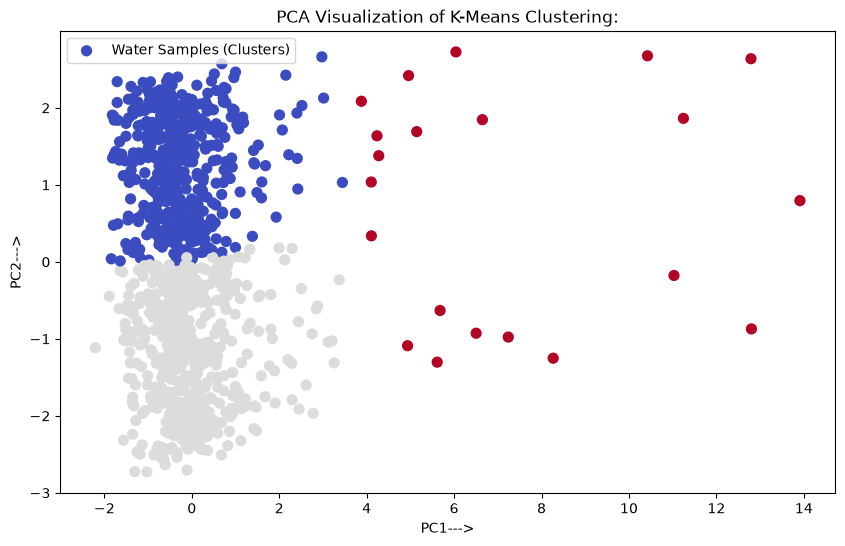

In [43]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scale)
pca_df = pd.DataFrame(x_pca,columns=['PC1','PC2']) #To store results in dataframe instead of np.array.
pca_df['Cluster'] = df_ml['Cluster']
print(pca_df.head())
print("Explained Variance Ratio of PCA:",pca.explained_variance_ratio_)
print("Total Variance Ratio:",pca.explained_variance_ratio_.sum())
#Visualization.
plt.figure(figsize=(10,6))
plt.title("PCA Visualization of K-Means Clustering:")
plt.xlabel("PC1--->")
plt.ylabel("PC2--->")
plt.scatter(pca_df['PC1'],pca_df['PC2'],cmap = 'coolwarm',c = df_ml['Cluster'], s = 50,label = 'Water Samples (Clusters)')
plt.legend()
plt.show()

## Isolation Forest:
#### It detects outliers or anomalies generally to detect polluted sample.

In [44]:
from sklearn.ensemble import IsolationForest
features = ['Temperature','BOD','DO','Nitrate','pH','Conductivity','Fluoride']
x = df_ml[features]
iso = IsolationForest(contamination=0.10,random_state=42)
anomaly = iso.fit_predict(x_scale)
df_ml['Pollution index'] = anomaly
print("",df_ml['Pollution index'].value_counts())
print(df_ml[df_ml['Pollution index'] == -1])

 Pollution index
 1    882
-1     98
Name: count, dtype: int64
     Station Code  Station Name  STATE  Temperature Min  Temperature Max  \
7          4354.0           101      0             25.0             27.0   
10         4377.0           107      0             27.0             27.0   
12         1518.0           113      0             23.0             27.0   
16         4384.0           124      0             22.0             23.0   
21         1517.0           158      0             23.0             26.0   
..            ...           ...    ...              ...              ...   
882        4218.0           765     28             22.0             25.0   
925        3457.0           313     30             19.0             20.0   
936        1938.0           200     31             27.0             32.0   
940        1779.0           215     31             26.0             29.0   
967        2530.0           511     31             61.0             67.0   

     pH Min  pH Max  Con

## Anomaly Detction Analysis:
Isolation Forest identified 98 water quality samples as potential anomalies, representing approximately 10% of the dataset. These samples show unusual combinations of water parameters compared to normal observations and may indicate possible contamination, measurement errors, or regions requiring further investigation.

In [45]:
#Showing anomaly entries/samples.
anomalies = df_ml[df_ml['Pollution index'] == -1]
anomalies[['Station Code', 'Station Name', 'STATE', 'Temperature Min',
       'Temperature Max', 'pH Min', 'pH Max', 'Conductivity (µmhos/cm) Min',
       'Conductivity (µmhos/cm) Max', 'Year', 'BOD', 'DO', 'Nitrate',
       'Fluoride', 'Temperature', 'pH', 'Conductivity', 'Cluster',
       'Pollution index']]
print(anomalies)

     Station Code  Station Name  STATE  Temperature Min  Temperature Max  \
7          4354.0           101      0             25.0             27.0   
10         4377.0           107      0             27.0             27.0   
12         1518.0           113      0             23.0             27.0   
16         4384.0           124      0             22.0             23.0   
21         1517.0           158      0             23.0             26.0   
..            ...           ...    ...              ...              ...   
882        4218.0           765     28             22.0             25.0   
925        3457.0           313     30             19.0             20.0   
936        1938.0           200     31             27.0             32.0   
940        1779.0           215     31             26.0             29.0   
967        2530.0           511     31             61.0             67.0   

     pH Min  pH Max  Conductivity (µmhos/cm) Min  Conductivity (µmhos/cm) Max  \
7     

## Random Forest:
To predict Normal or Anomalous water samples.

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
x = df_ml[["Temperature","pH","Conductivity","BOD","DO","Nitrate","Fluoride"]]
y = df_ml['Pollution index']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)
rf = RandomForestClassifier(random_state=42)
rf.fit(x_train,y_train)
y_pred = rf.predict(x_test)
acc = accuracy_score(y_test,y_pred)
acc

0.9693877551020408

### Creating Classification report and Confusion matrix:

Classification Report:
{'Normal': {'precision': 0.9786096256684492, 'recall': 0.9891891891891892, 'f1-score': 0.9838709677419355, 'support': 185.0}, 'Anomalous': {'precision': 0.7777777777777778, 'recall': 0.6363636363636364, 'f1-score': 0.7, 'support': 11.0}, 'accuracy': 0.9693877551020408, 'macro avg': {'precision': 0.8781937017231135, 'recall': 0.8127764127764128, 'f1-score': 0.8419354838709677, 'support': 196.0}, 'weighted avg': {'precision': 0.9673384505317278, 'recall': 0.9693877551020408, 'f1-score': 0.9679394338380514, 'support': 196.0}}
Confusion Matrix:
[[183   2]
 [  4   7]]
              precision    recall  f1-score     support
Normal         0.978610  0.989189  0.983871  185.000000
Anomalous      0.777778  0.636364  0.700000   11.000000
accuracy       0.969388  0.969388  0.969388    0.969388
macro avg      0.878194  0.812776  0.841935  196.000000
weighted avg   0.967338  0.969388  0.967939  196.000000


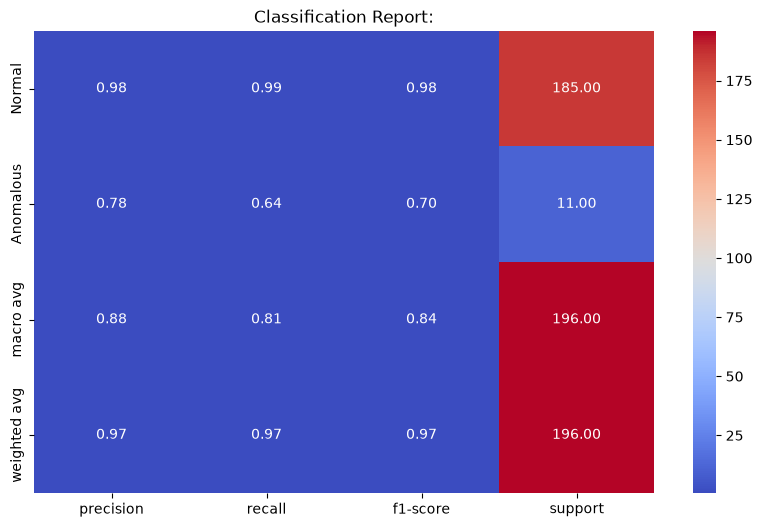

In [47]:
from sklearn.metrics import classification_report, confusion_matrix
#Printing both.
print("Classification Report:")
cr = classification_report(y_test, y_pred, labels = [1,-1],target_names = ["Normal","Anomalous"],output_dict=True)
print(cr)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels = [1,-1]))
df_cr = pd.DataFrame(cr).transpose()
print(df_cr)
df_cr_plot = df_cr.drop( index="accuracy", errors="ignore" )
plt.figure(figsize=(10,6))
plt.title("Classification Report:")
sns.heatmap(df_cr_plot, annot=True,cmap = 'coolwarm', fmt = ".2f")
plt.show()

### Model Analysis:
The Random Forest Classifier was used to classify water samples as Normal or Anomalous using Temperature, pH, Conductivity, BOD, DO, Nitrate, and Fluoride as input features. The dataset was divided into 80% training and 20% testing data, and the model was trained using 100 decision trees. It achieved an accuracy of 96.94%, showing strong overall classification performance. The model was further evaluated using the classification report and confusion matrix to examine its performance for both Normal and Anomalous water samples.

## K-Nearest Neighbor:

#### We will predict DO(Disolved Oxygen) in samples:

In [48]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
features = ['Temperature','BOD','pH','Conductivity','Fluoride','Nitrate']
x = df_ml[features]
x_scale = scaler.fit_transform(x)
y = df_ml['DO']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(x_train,y_train)
y_pred = knn.predict(x_test)
print("Mean Absolute Error:",mean_absolute_error(y_test,y_pred))
print("Mean Squared Error:",mean_squared_error(y_test,y_pred))
print("R2 Score:",r2_score(y_test,y_pred))

Mean Absolute Error: 0.8142720467223045
Mean Squared Error: 0.950911676235055
R2 Score: -0.13831250654683203


In [49]:
#Predictions.
result = pd.DataFrame({"Actual DO":y_test.values,"Predicted DO Values":y_pred})
result['Prediction error'] = (result['Actual DO'] - result['Predicted DO Values'])
print("Actual DO vs Predicted DO:\n",result.head(10))

Actual DO vs Predicted DO:
    Actual DO  Predicted DO Values  Prediction error
0   5.367004             6.724868         -1.357863
1   7.148184             6.086018          1.062166
2   5.074002             6.219018         -1.145016
3   7.942697             6.083617          1.859080
4   5.483217             6.897551         -1.414335
5   5.791022             7.346646         -1.555625
6   8.150569             6.433691          1.716878
7   6.311314             6.427258         -0.115944
8   7.740292             7.279362          0.460931
9   7.460870             5.864262          1.596608


### KNN Analysis:
The KNN Regressor was used to predict Dissolved Oxygen (DO) using BOD, Nitrate, Fluoride, Temperature, pH, and Conductivity as input features. The data was standardized because KNN is distance-based and then divided into 80% training and 20% testing data. The model used 5 nearest neighbors, and its performance was evaluated using MAE, MSE and R² score. Lower error values and an R² score closer to 1 indicate better prediction performance.

## Visualization and graph, chart plot:

In [50]:
#Decoding categorical colums.
for col in ['STATE','Station Name']:
    df_ml[col] = df_visual[col]
df_visual = df_ml

### 1. State-wise Pollution Distribution:

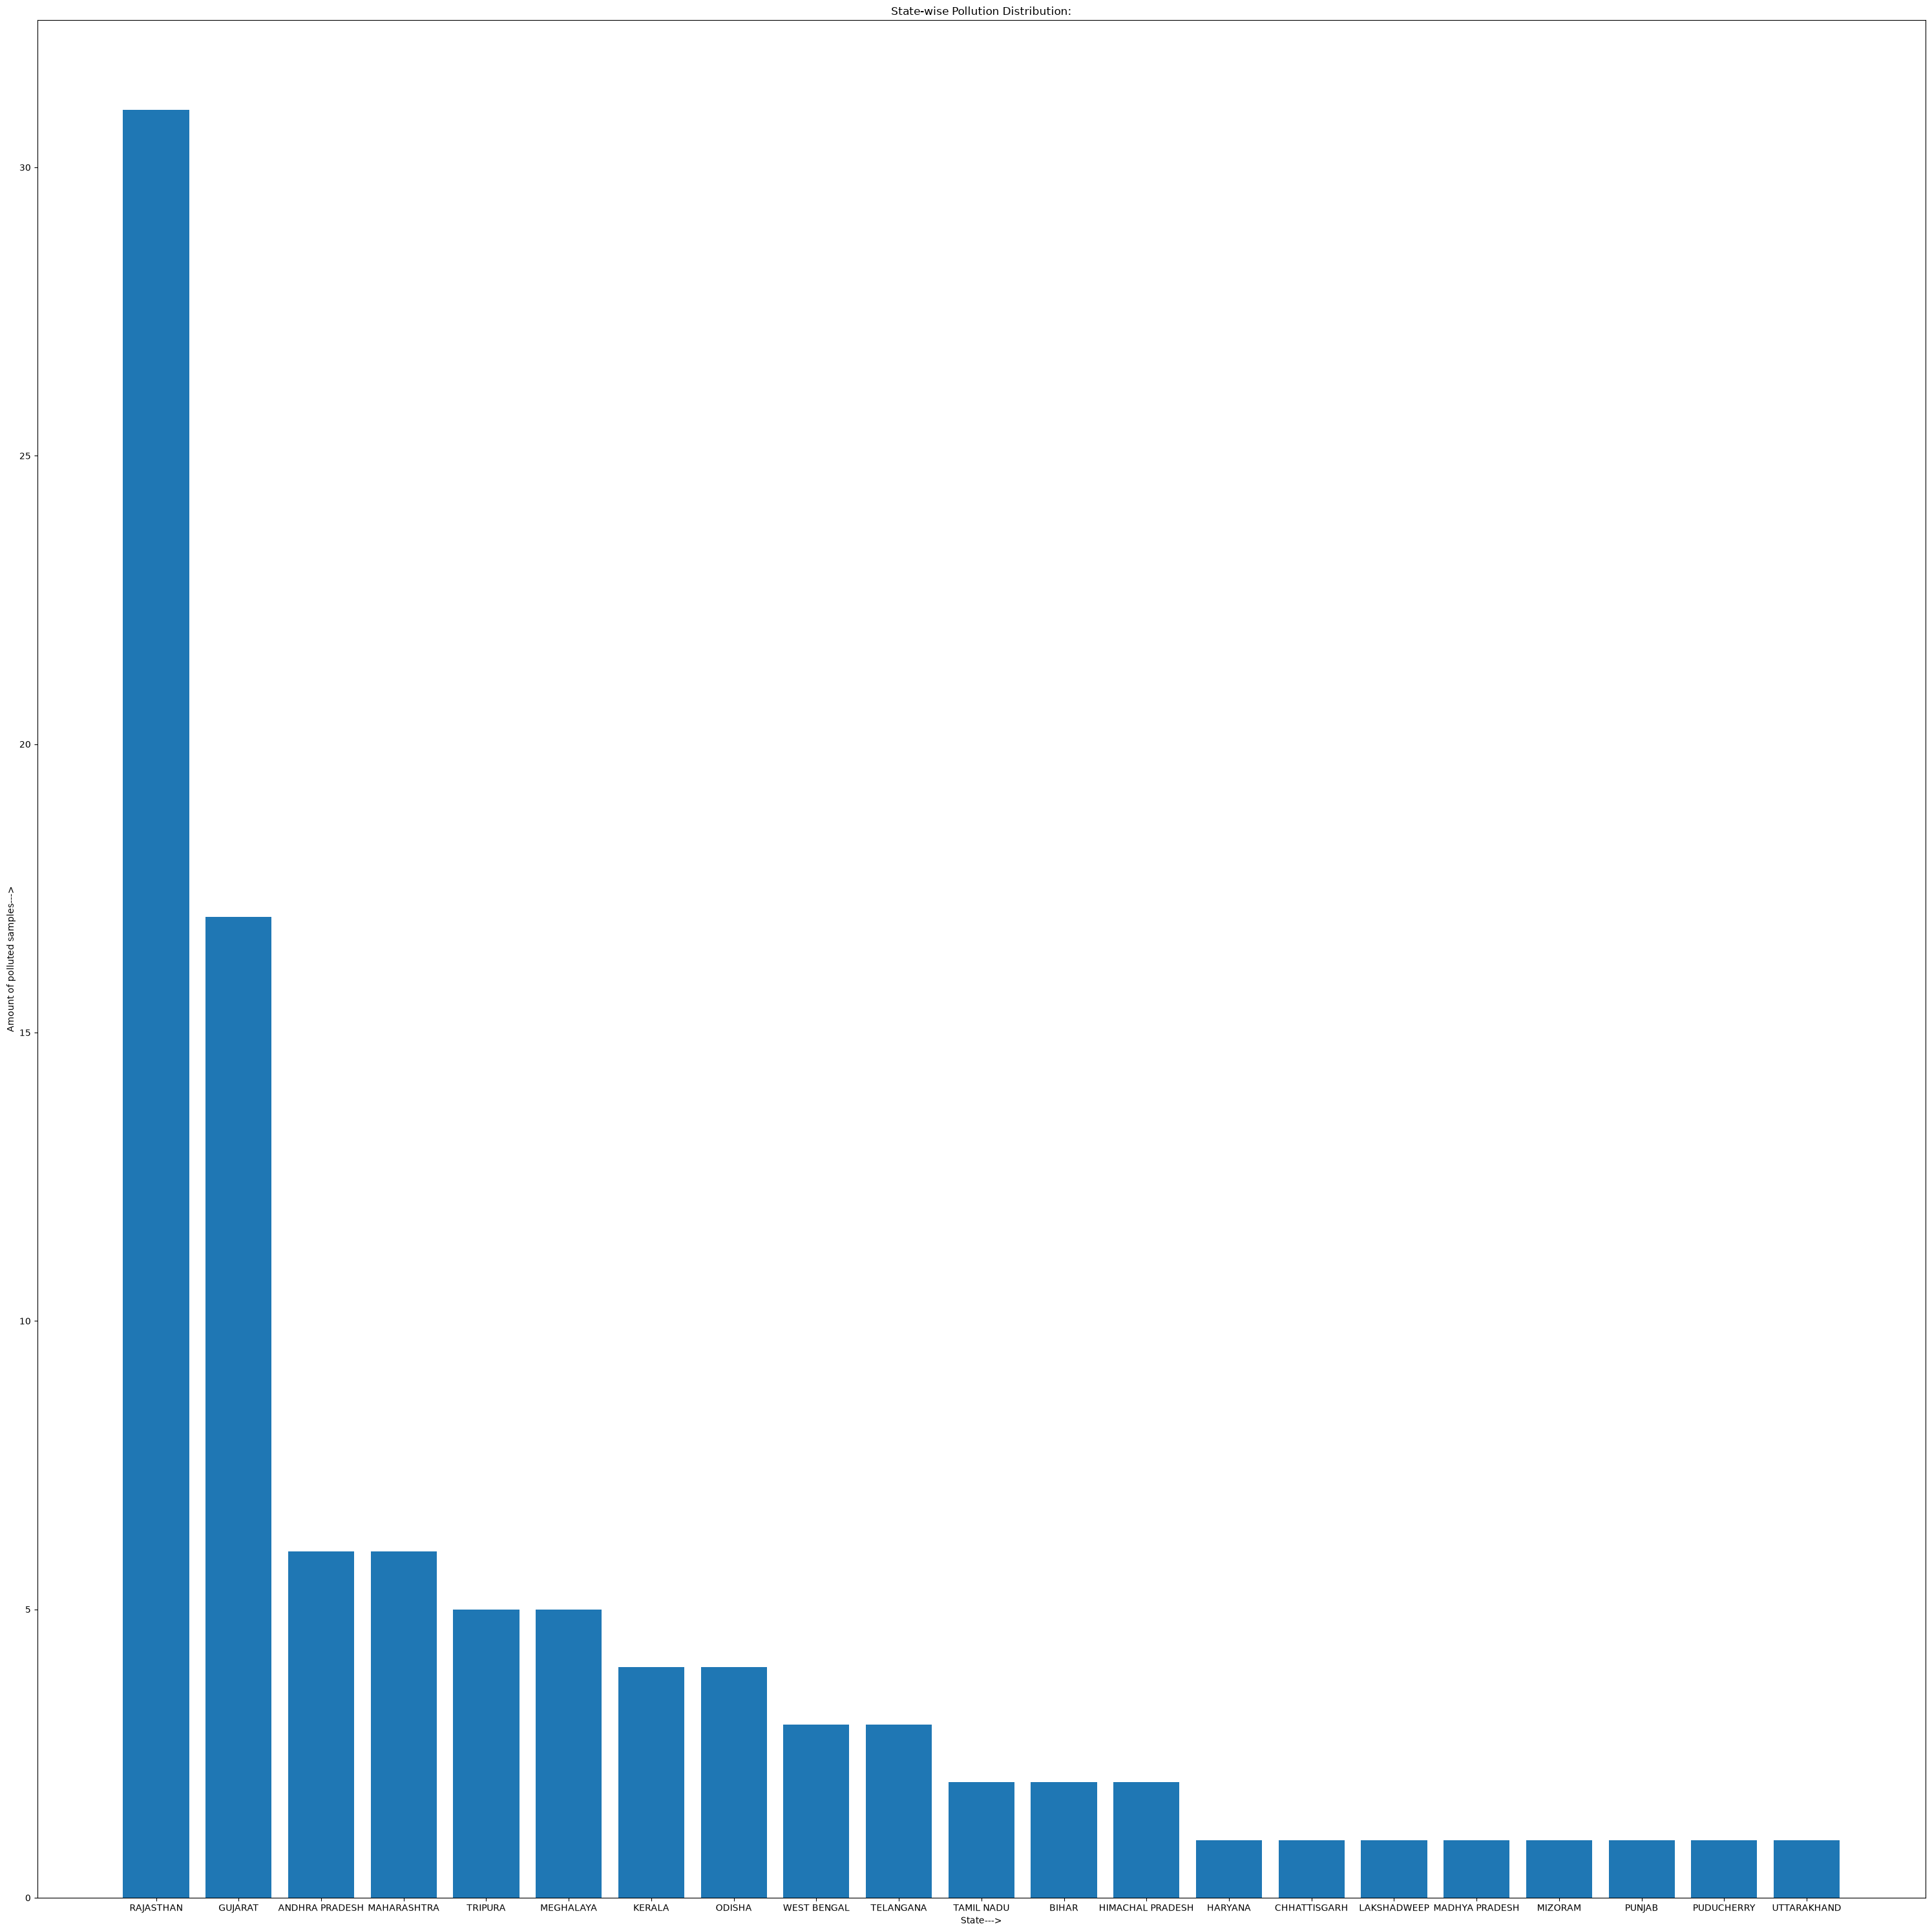

In [51]:
polluted_df = df_ml[df_ml['Pollution index'] == -1]
state_pol = (polluted_df.groupby('STATE').size().sort_values(ascending=False))
plt.figure(figsize=(30,30))
plt.bar(state_pol.index,state_pol.values)
plt.title("State-wise Pollution Distribution:")
plt.xlabel("State--->")
plt.ylabel("Amount of polluted samples--->")
plt.tight_layout()
plt.show()

#### Analysis:
This graph shows the number of anomalous water stations in each state. States with taller bars have a higher number of potentially polluted or unusual water samples and may require greater monitoring.

### 2. State-wise Water Quality Index:

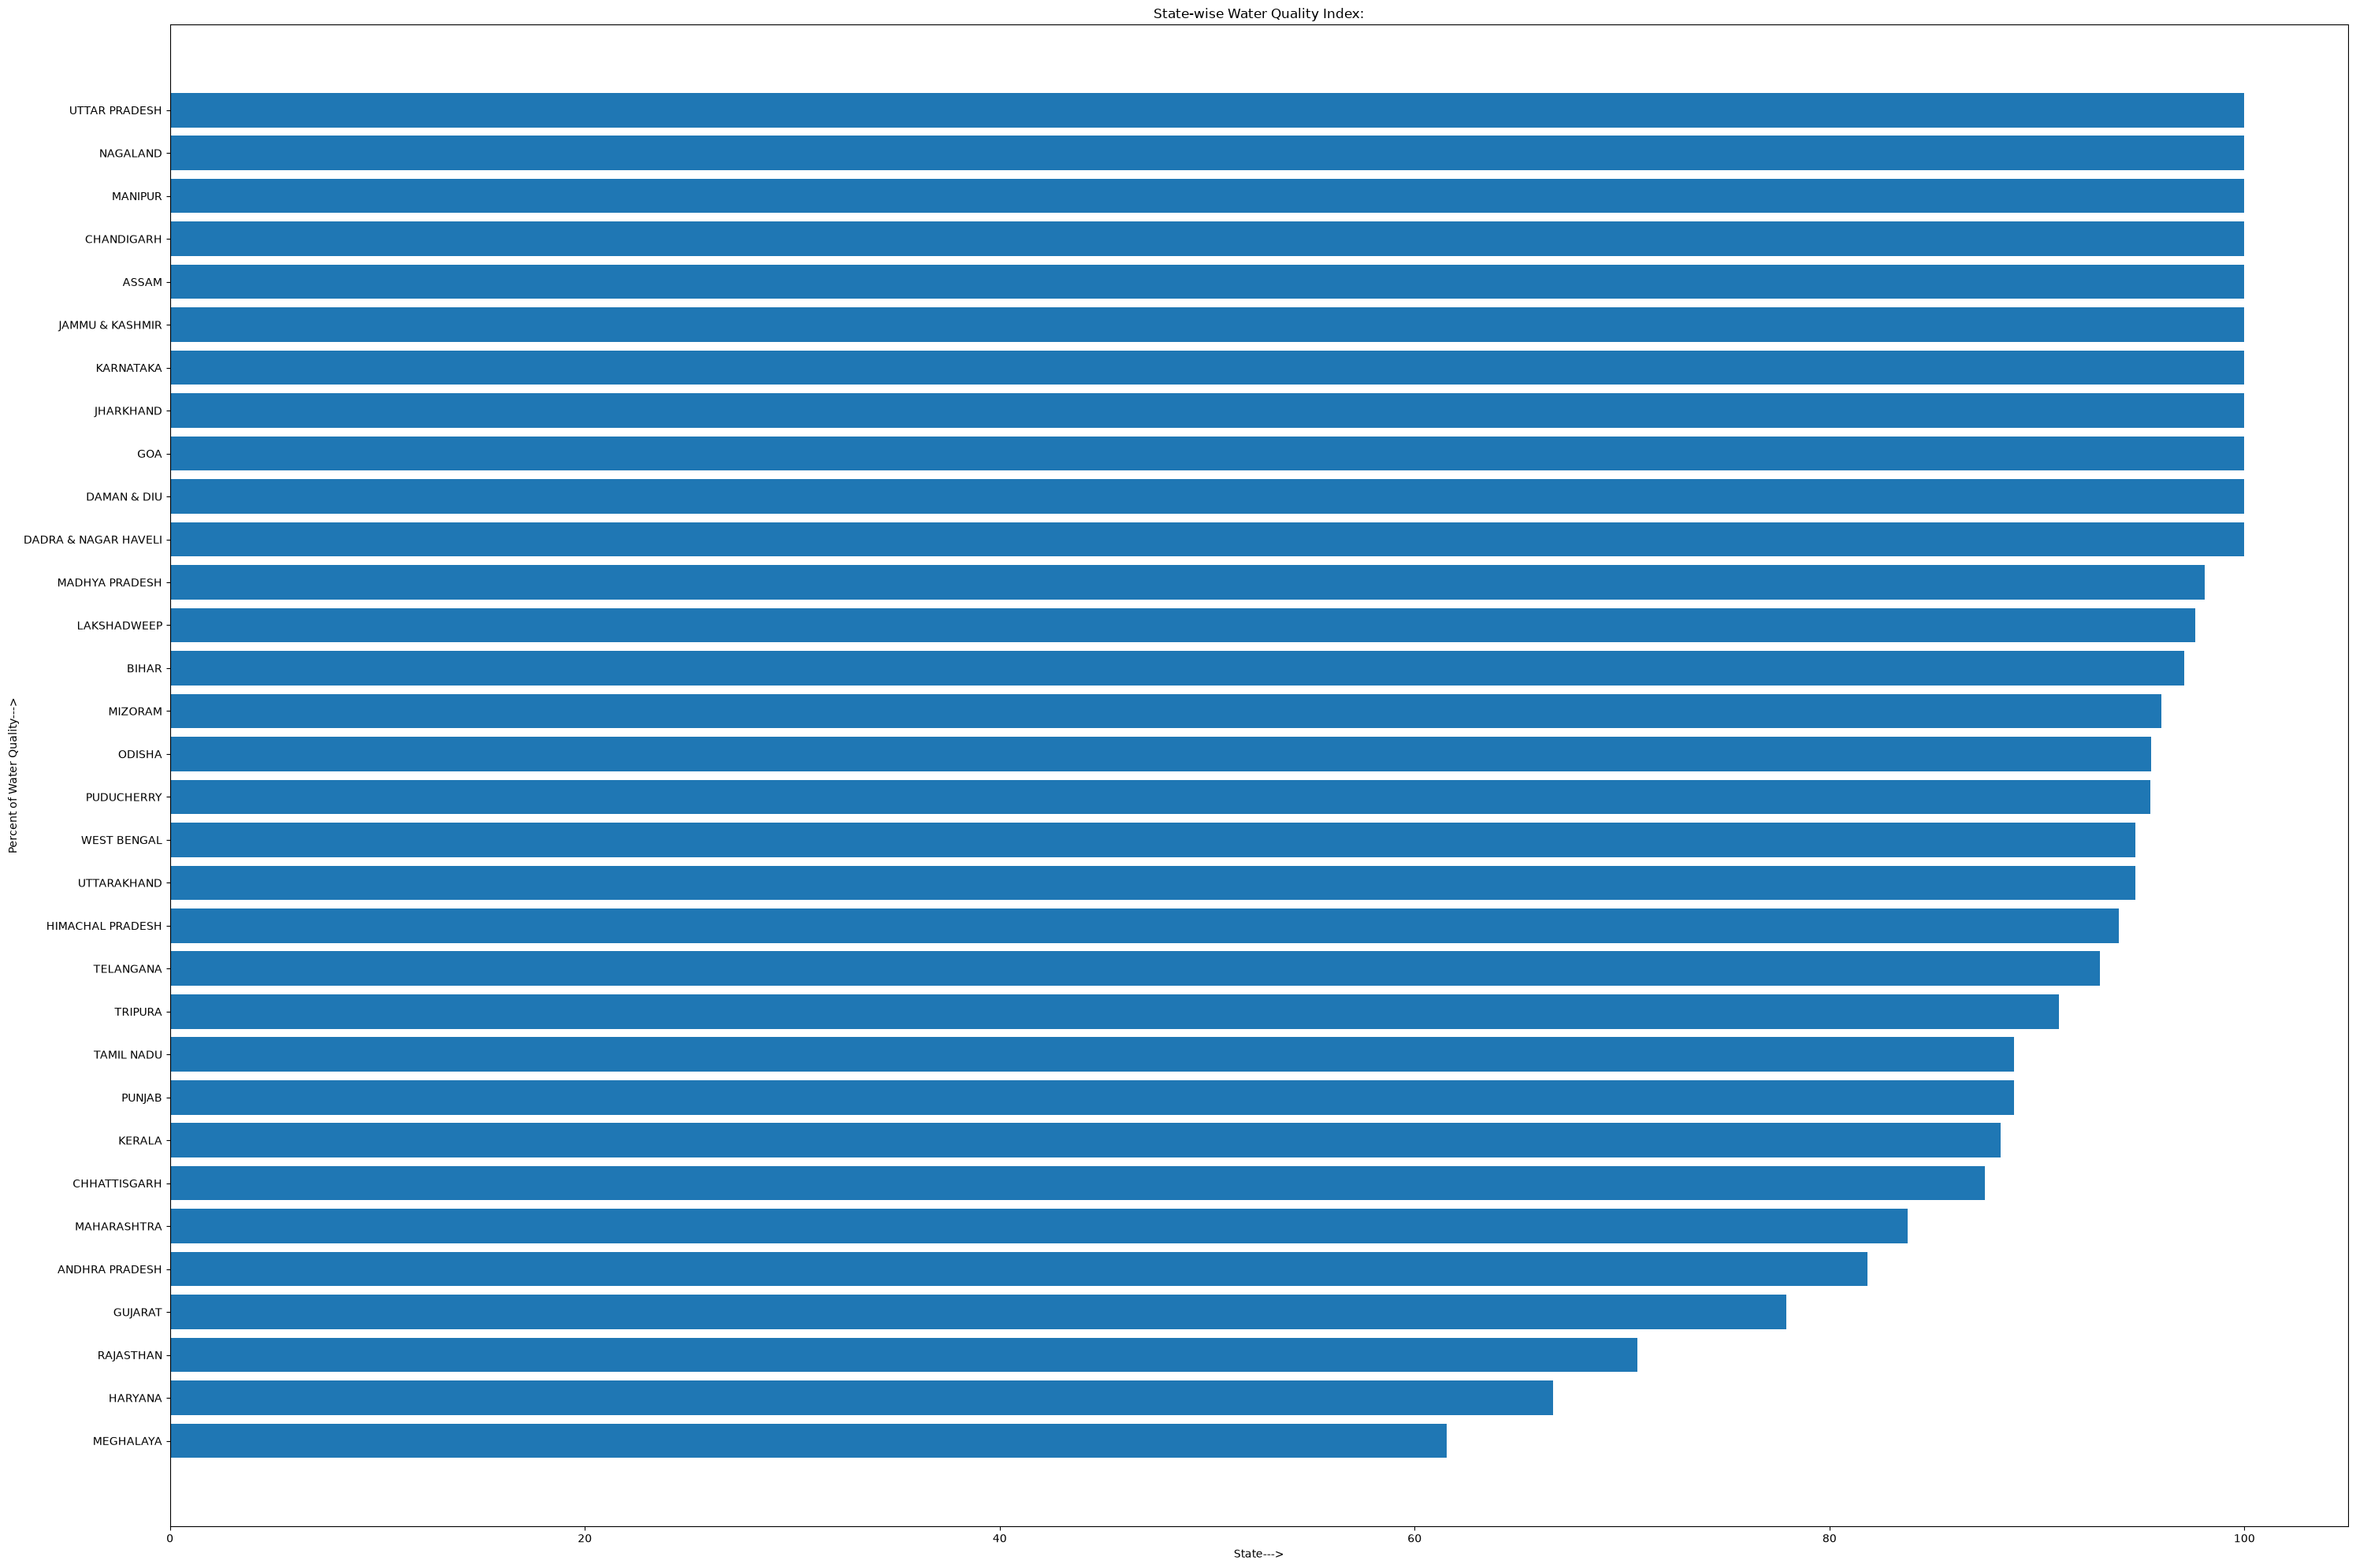

In [52]:
state_quality = (df_ml.groupby('STATE')['Pollution index'].apply(lambda x: (x == 1).mean()*100).sort_values())
plt.figure(figsize=(30,20))
plt.barh(state_quality.index,state_quality.values)
plt.title("State-wise Water Quality Index:")
plt.ylabel("Percent of Water Quality--->")
plt.xlabel("State--->")
plt.tight_layout()
plt.show()

### Analysis:

The graph compares the percentage of Normal water samples across different states. A higher score indicates that a larger proportion of water samples in that state were classified as Normal.

### 3. Normal vs Anomalous Water Samples:

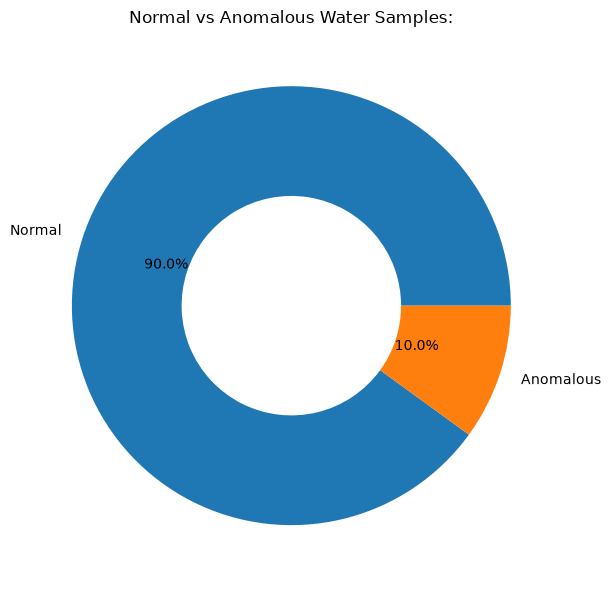

In [53]:
plt.figure(figsize=(10,6))
water_status = (df_visual['Pollution index'].map({1:"Normal",-1:"Anomalous"}).value_counts())
plt.pie(water_status.values,labels = water_status.index, autopct = "%1.1f%%",wedgeprops={"width":0.5})
plt.title("Normal vs Anomalous Water Samples:")
plt.tight_layout()
plt.show()

### Analysis: 
This donut chart shows the percentage of Normal and Anomalous water samples detected using the Pollution Index. It provides a quick overview of the overall water-quality condition in the dataset.

### 4. Correlation Heatmap:

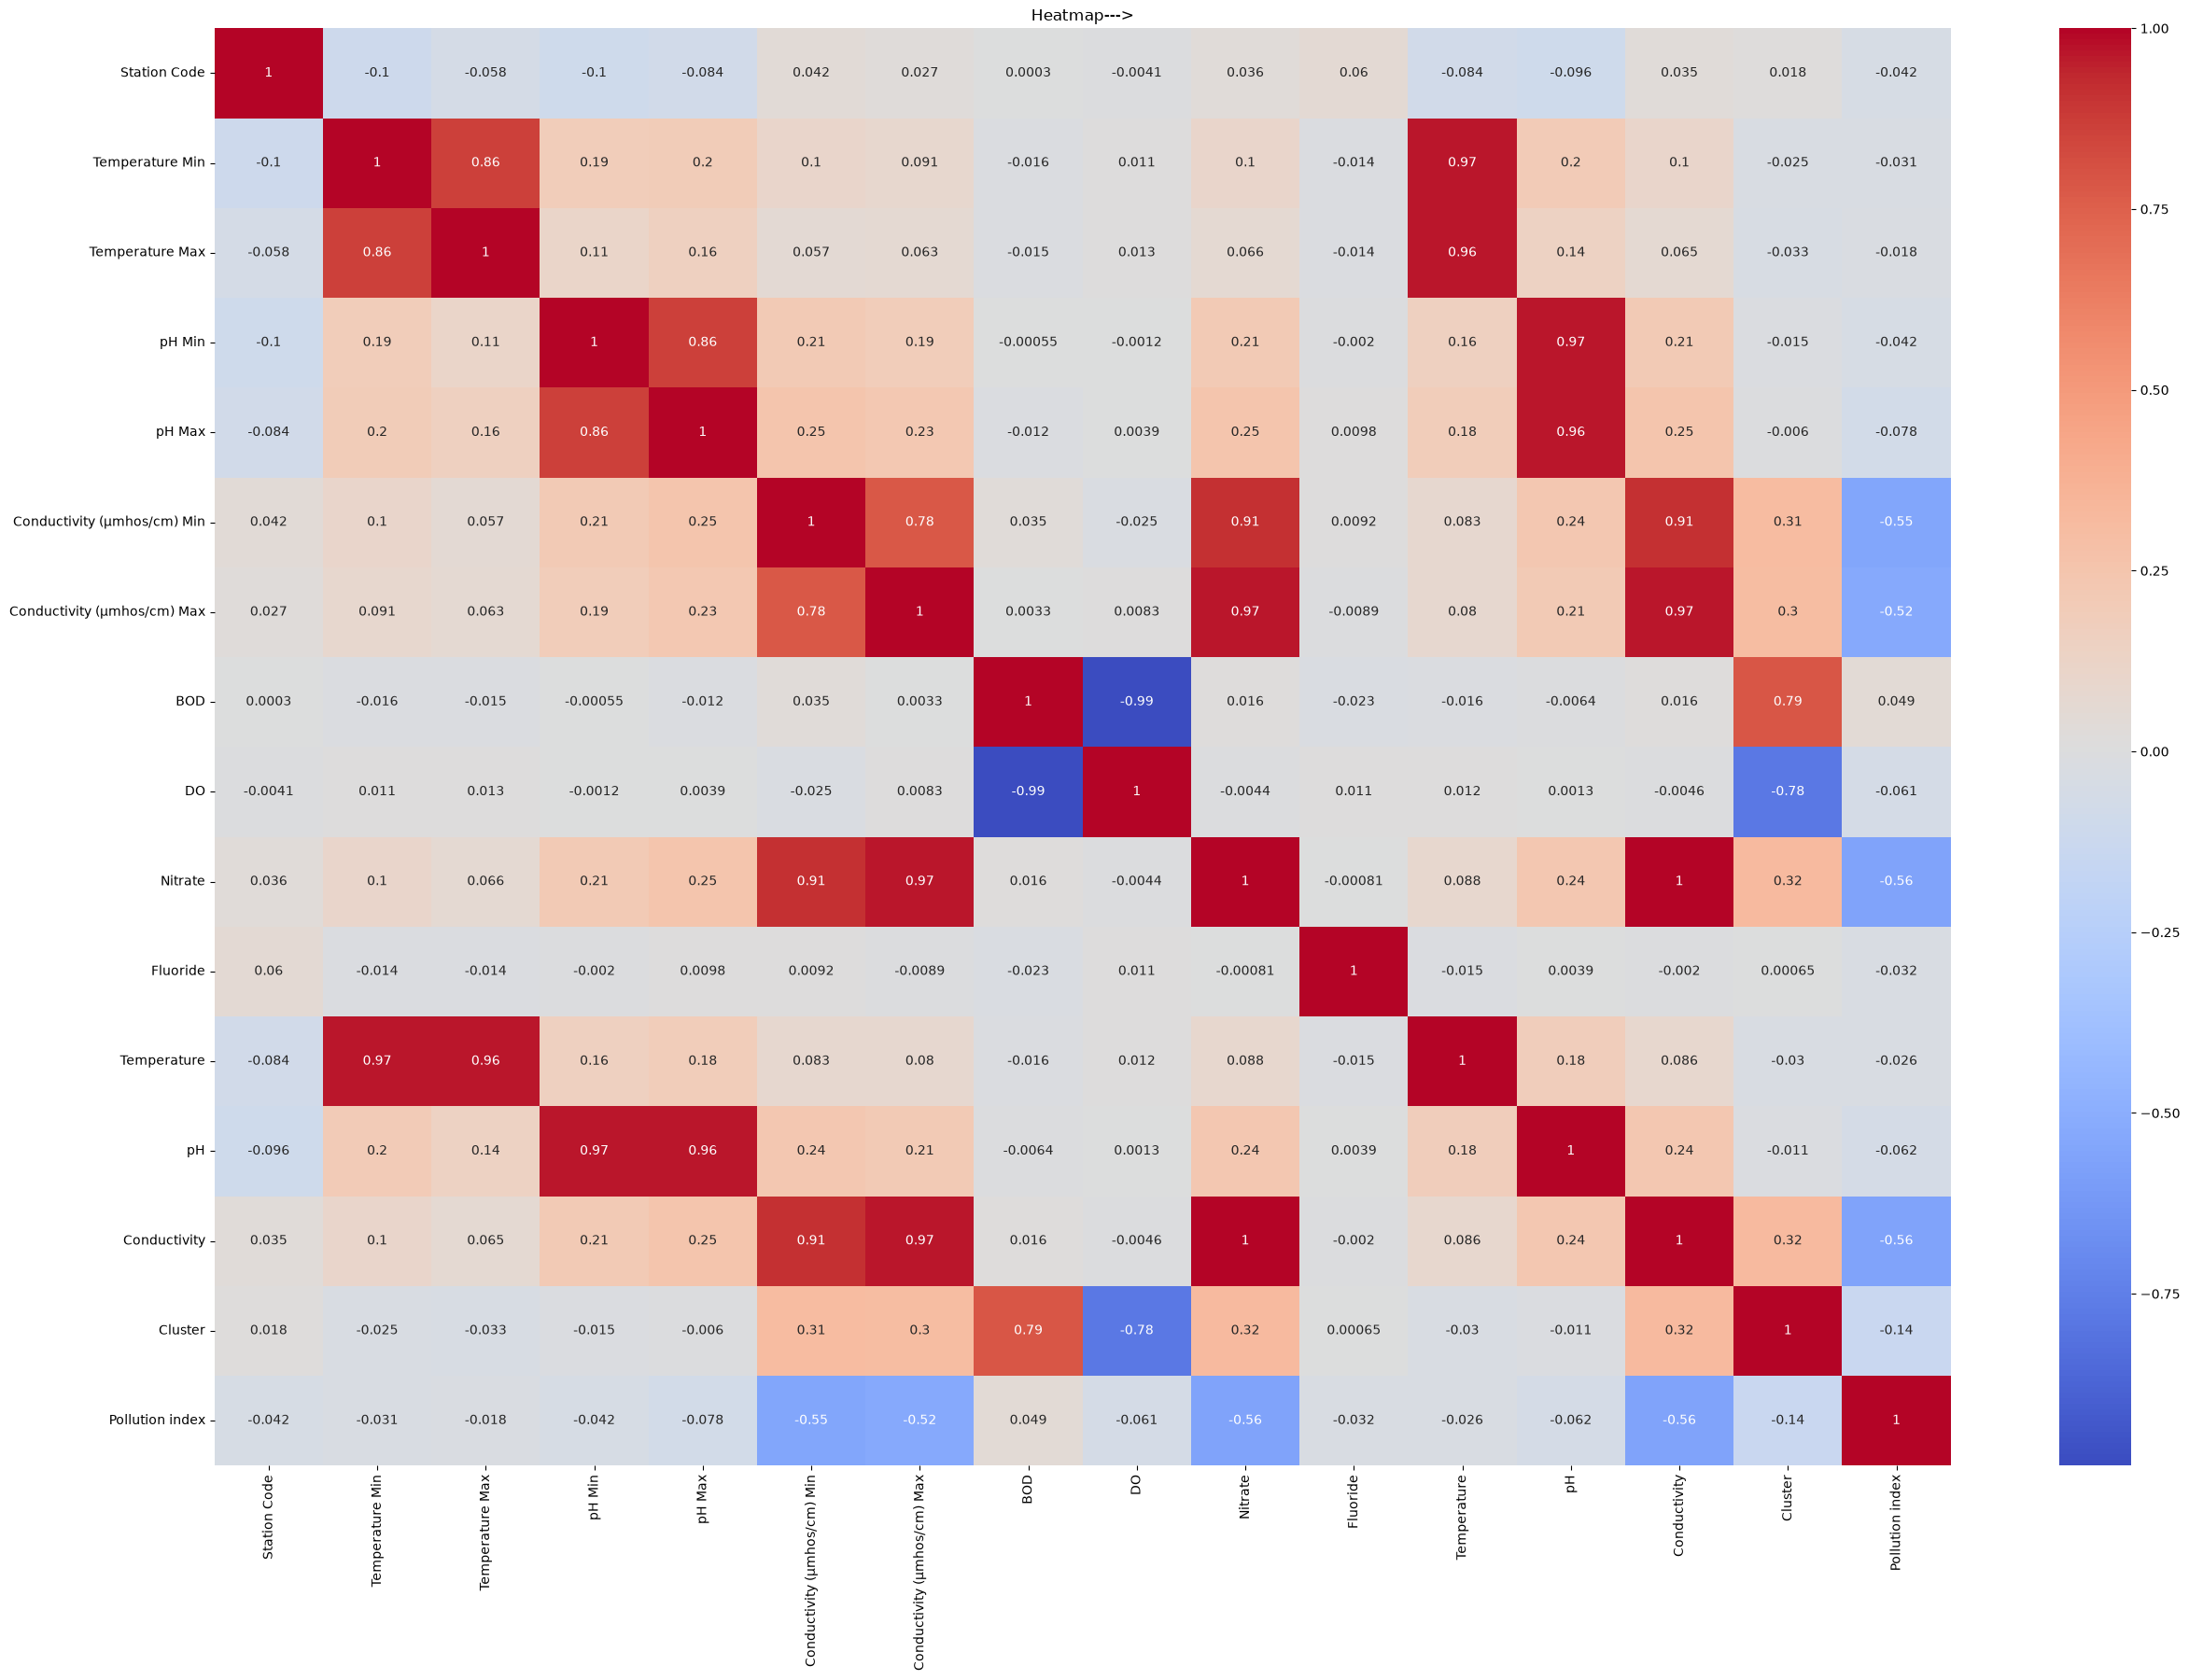

In [54]:
df_num = df_visual.select_dtypes(include = 'number').drop(columns=['Year'] ,errors = "ignore")
corr = df_num.corr()
plt.figure(figsize=(30,20))
sns.heatmap(corr, annot=True,cmap='coolwarm')
plt.title("Heatmap--->")
plt.show()

### Analysis:
The heatmap displays the strength and direction of relationships between different water-quality parameters. Values closer to 1 or -1 indicate stronger positive or negative relationships, while values close to 0 indicate a weak relationship.

### 5. pH vs Conductivity:

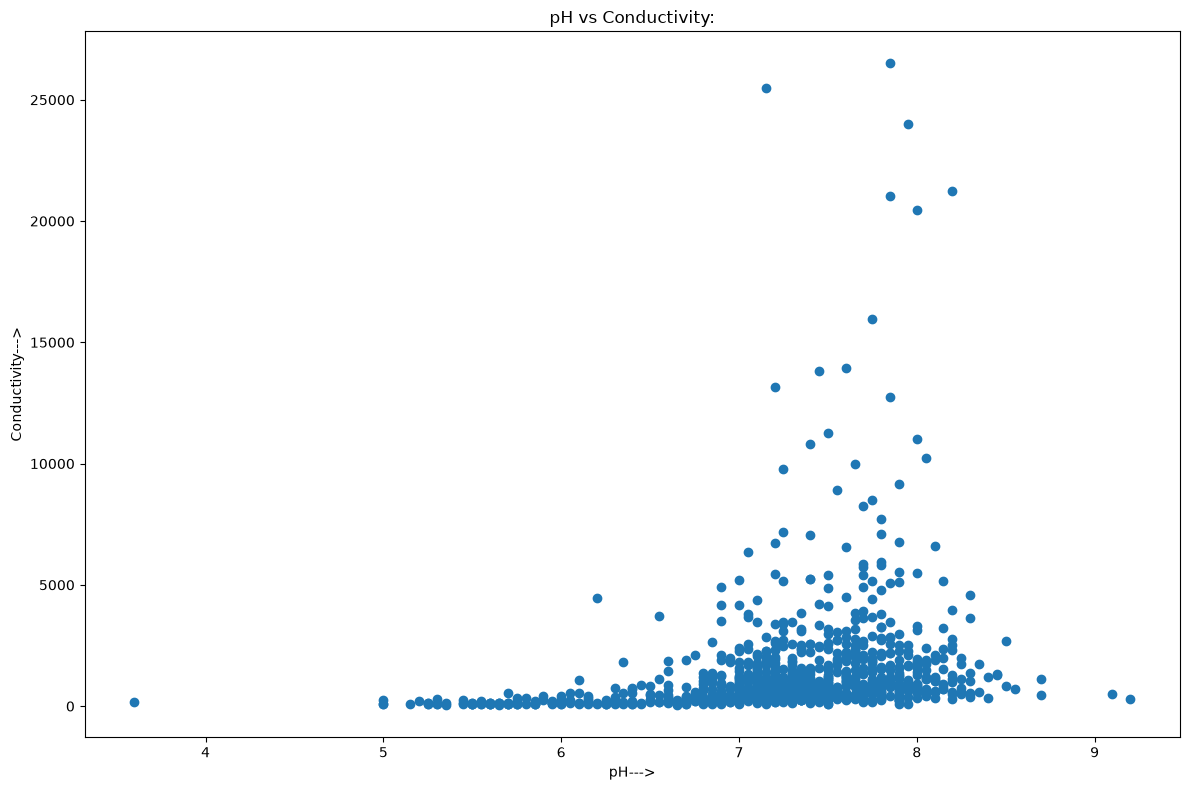

In [55]:
plt.figure(figsize=(12,8))
plt.scatter(df_visual['pH'], df_visual['Conductivity'])
plt.xlabel("pH--->")
plt.ylabel("Conductivity--->")
plt.title("pH vs Conductivity:")
plt.tight_layout()
plt.show()

### Analysis:
This scatter plot shows how pH and conductivity vary together. The spread of points helps identify possible relationships and unusual water samples.

### 6. Conductivity Distribution:

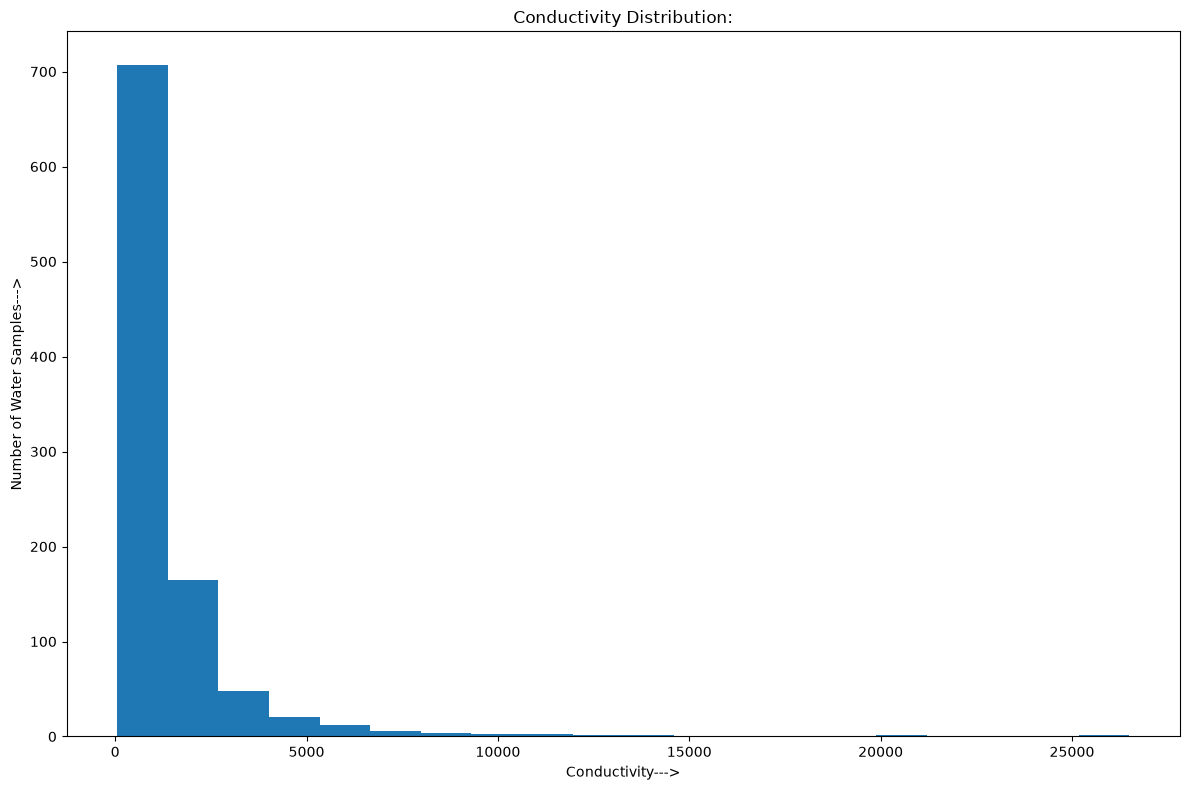

In [56]:
plt.figure(figsize=(12,8))
plt.hist(df_visual['Conductivity'], bins=20)
plt.xlabel("Conductivity--->")
plt.ylabel("Number of Water Samples--->")
plt.title("Conductivity Distribution:")
plt.tight_layout()
plt.show()

### Analysis:
The histogram shows the frequency distribution of conductivity values. It helps identify the most common range and any unusually high or low values.

### 7. Temperature vs Conductivity:

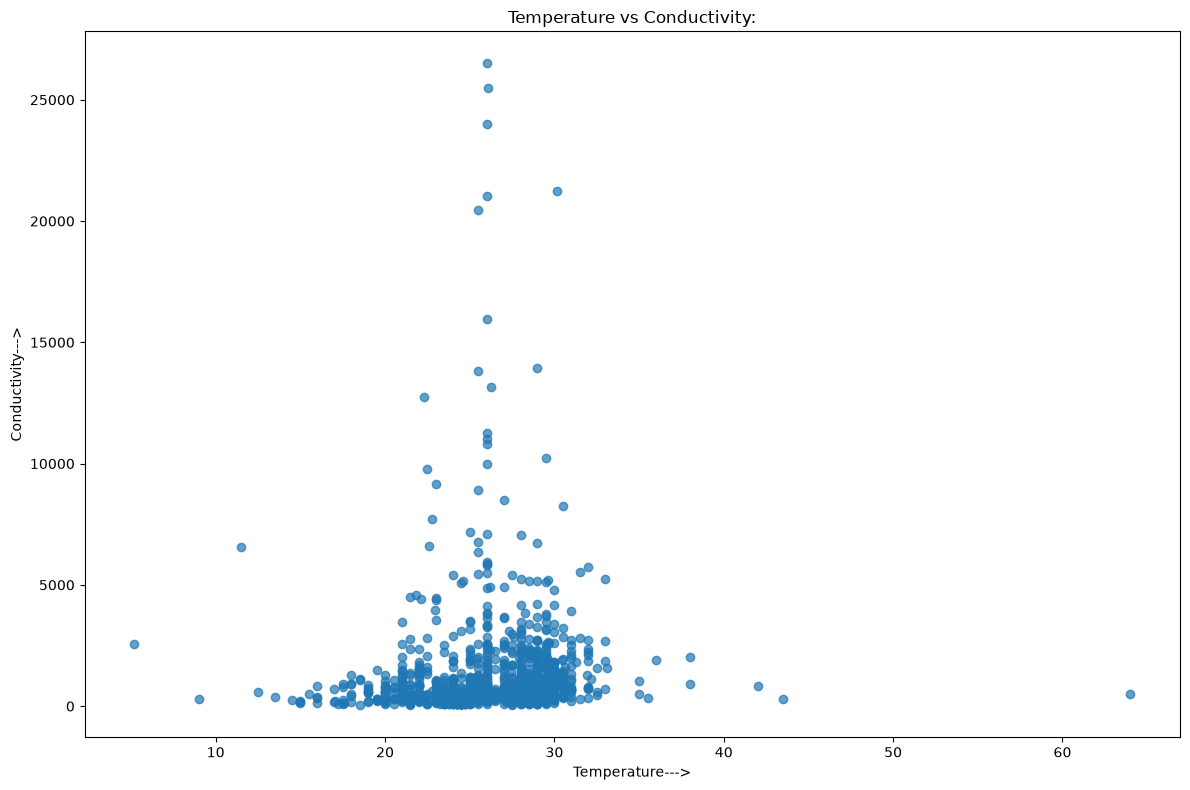

In [57]:
plt.figure(figsize=(12,8))
plt.scatter(df_visual['Temperature'], df_visual['Conductivity'], alpha=0.7)
plt.xlabel("Temperature--->")
plt.ylabel("Conductivity--->")
plt.title("Temperature vs Conductivity:")
plt.tight_layout()
plt.show()

### Analysis:
This scatter plot shows whether temperature changes are associated with changes in conductivity. A clear pattern may indicate a relationship between the two parameters.

### 8. Top 10 most cleanest states:

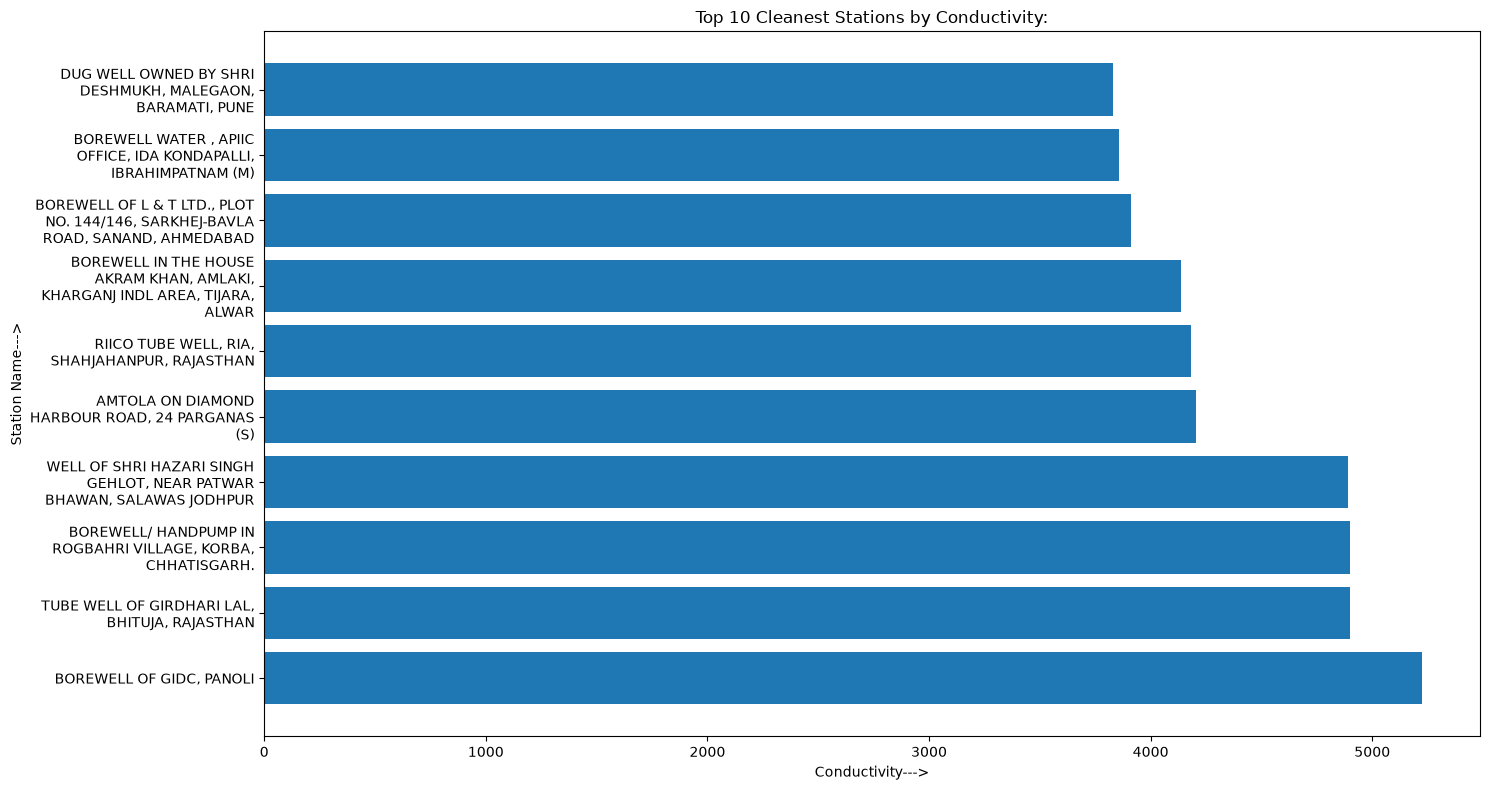

In [58]:
top_10 = df_visual[df_visual['Pollution index'] == 1].nlargest(10, 'Conductivity')
plt.figure(figsize=(15,8))
plt.barh(top_10['Station Name'], top_10['Conductivity'])
plt.xlabel("Conductivity--->")
plt.ylabel("Station Name--->")
plt.title("Top 10 Cleanest Stations by Conductivity:")
plt.tight_layout()
plt.show()

### Analysis: 
This graph displays the ten normal stations with the lowest conductivity values. It speciallly shows most cleanest states by water quality.

### 9. Top 10 most Anomlous states:

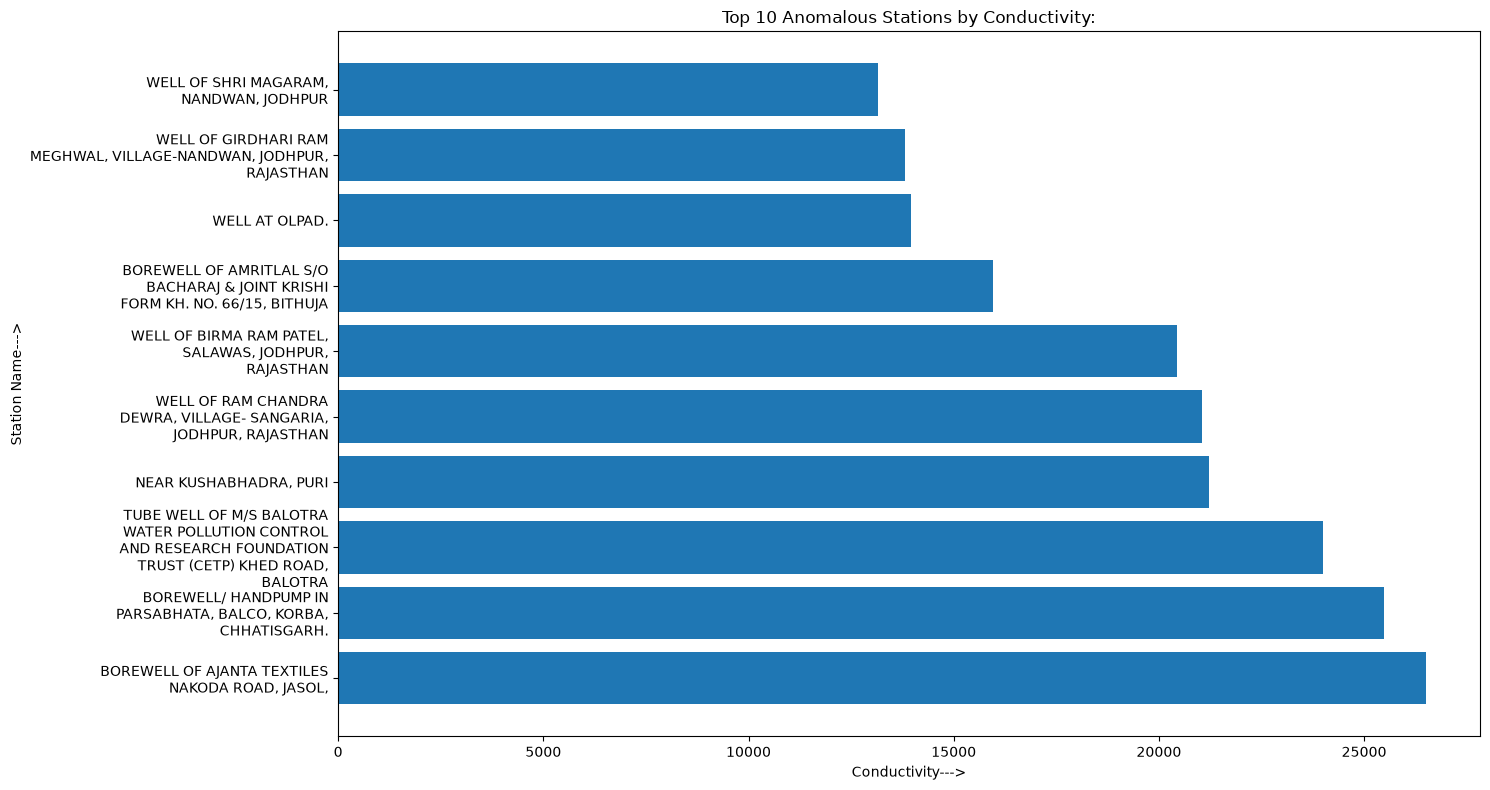

In [59]:
top_10 = df_visual[df_visual['Pollution index'] == -1].nlargest(10, 'Conductivity')
plt.figure(figsize=(15,8))
plt.barh(top_10['Station Name'], top_10['Conductivity'])
plt.xlabel("Conductivity--->")
plt.ylabel("Station Name--->")
plt.title("Top 10 Anomalous Stations by Conductivity:")
plt.tight_layout()
plt.show()

### Analysis:
This graph highlights the ten anomalous stations with the highest conductivity values. These stations can be prioritized for detailed water-quality investigation and monitoring.

### 10. Average DO by State:

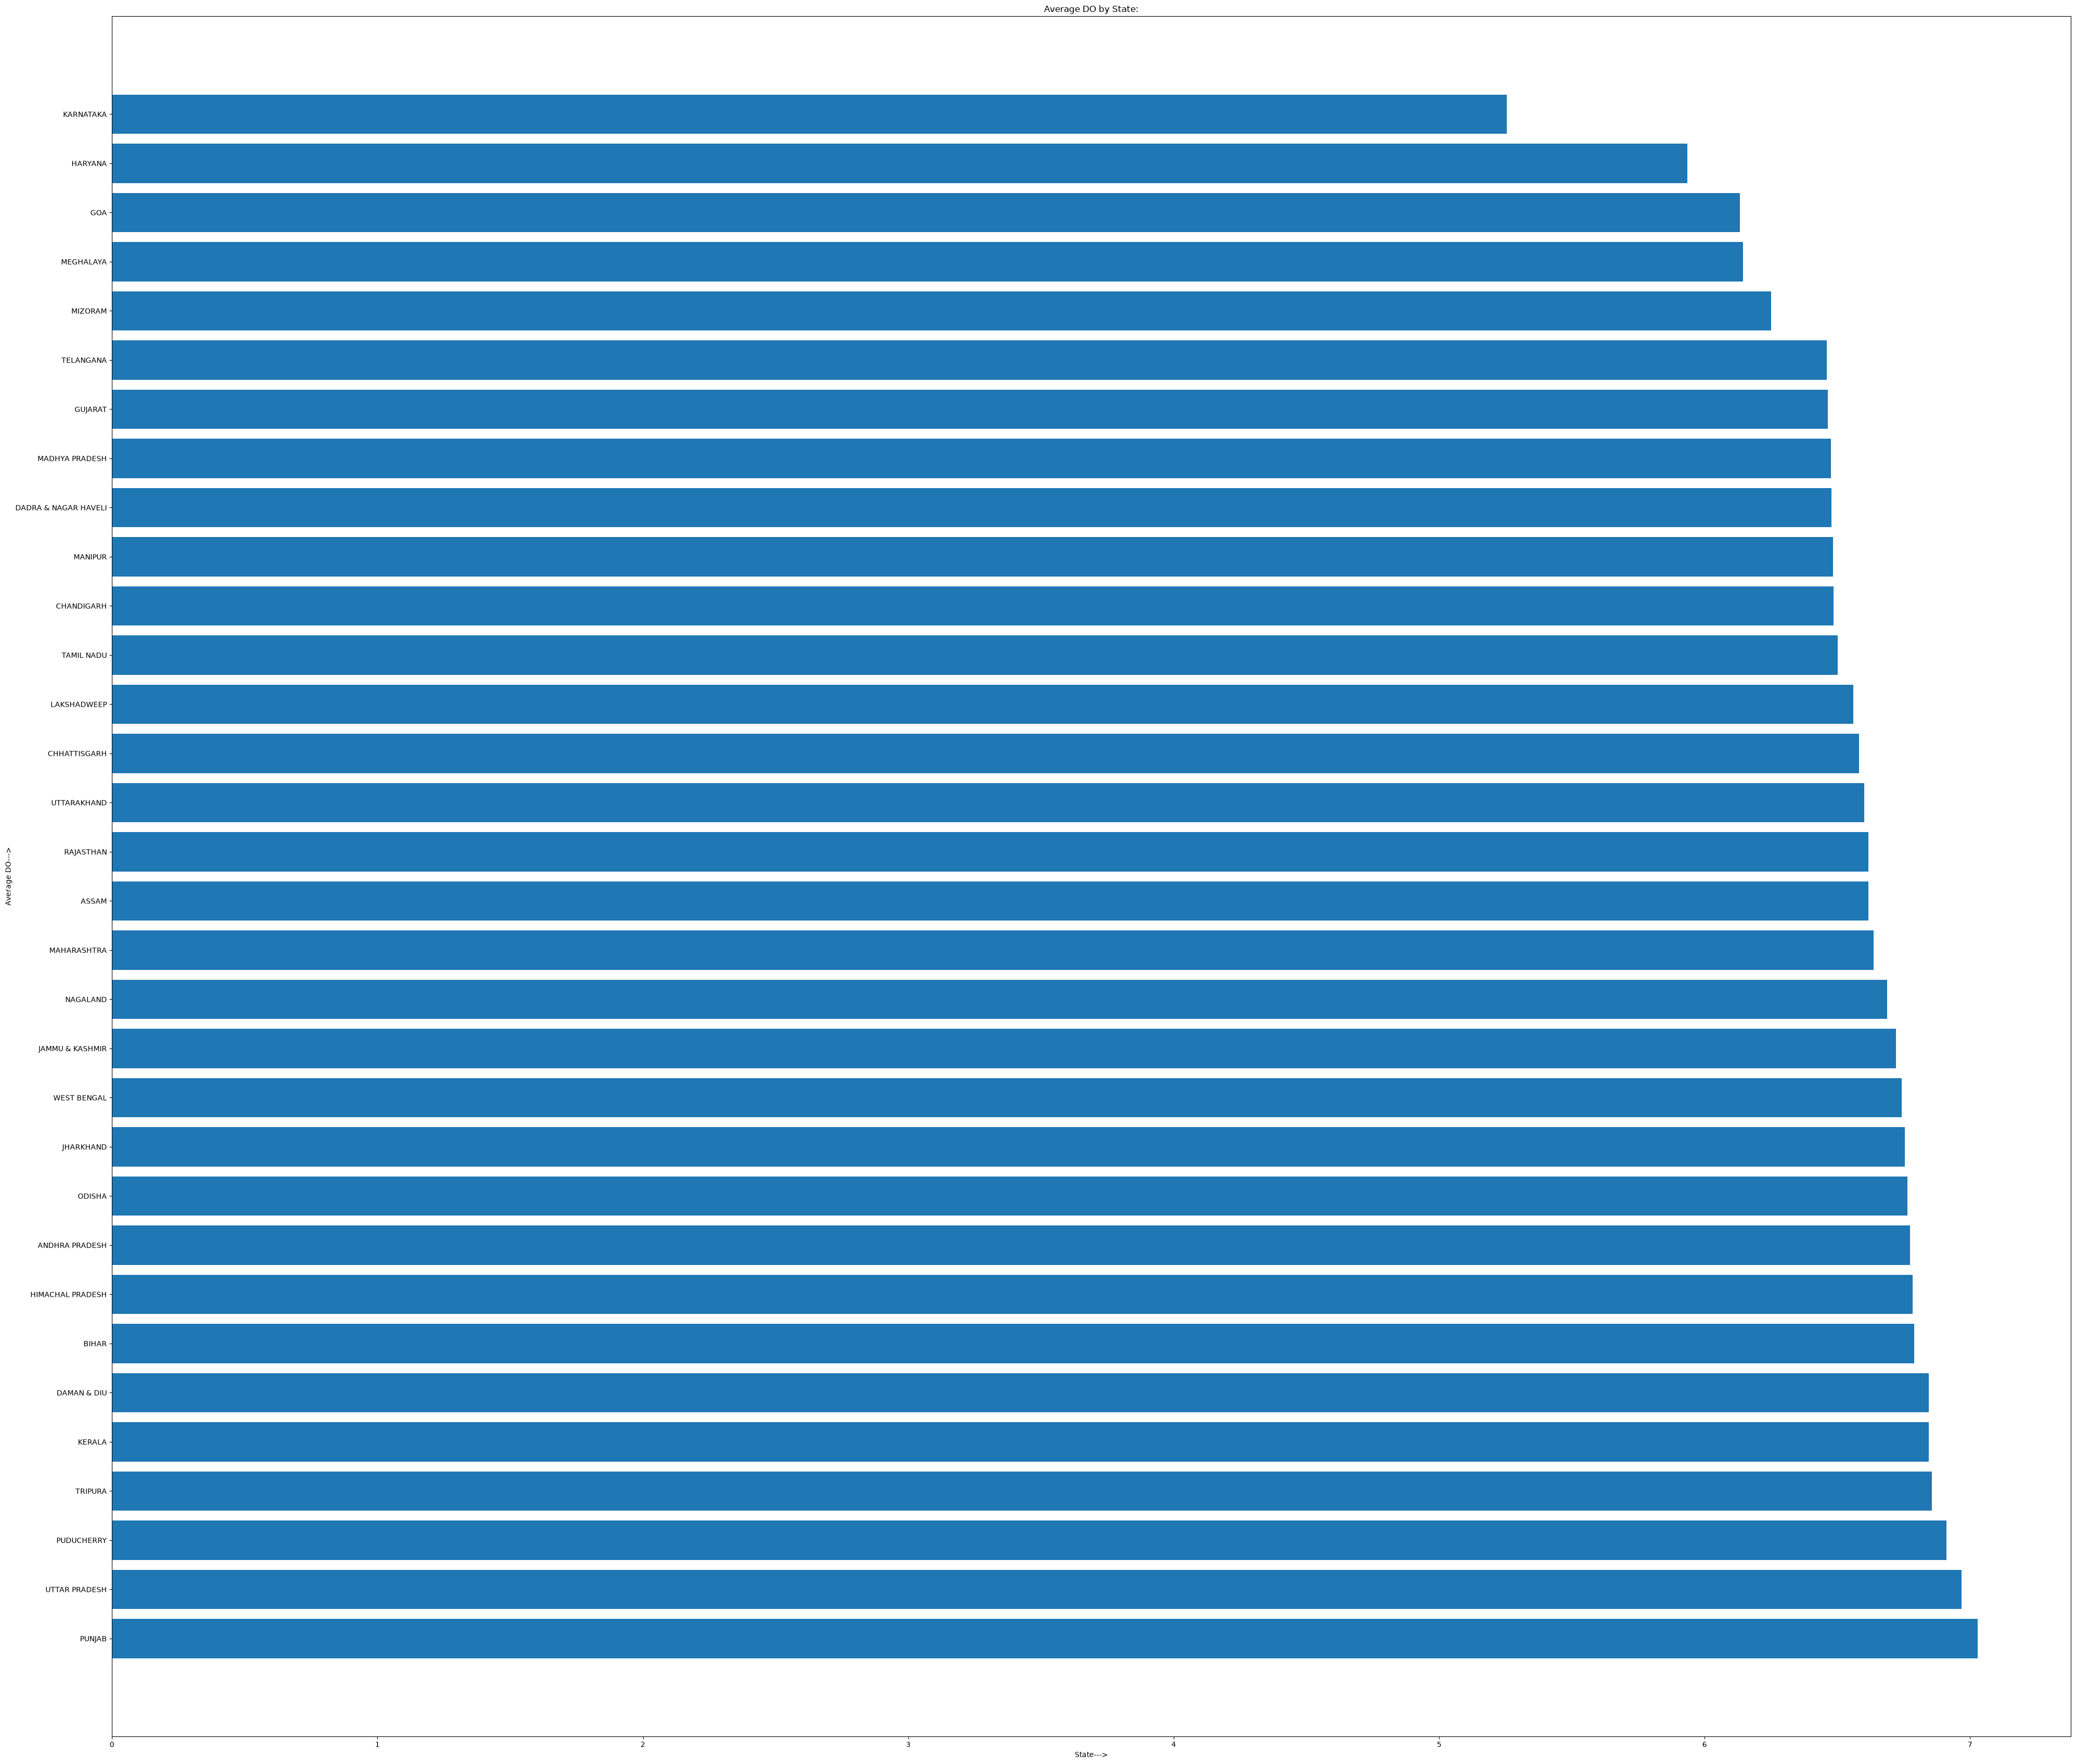

In [60]:
avg_do = df_visual.groupby('STATE')['DO'].mean().sort_values(ascending=False)
plt.figure(figsize=(40,34))
plt.barh(avg_do.index,avg_do.values)
plt.title("Average DO by State:")
plt.xlabel("State--->")
plt.ylabel("Average DO--->")
plt.tight_layout()
plt.show()

### Analysis:
This graph compares the average Dissolved Oxygen level across different states. States with lower average DO may require closer water-quality monitoring because DO is an important indicator of water health.

## Saving ML Models:

In [61]:
import joblib
joblib.dump(kmeans, "/home/abhinav/Desktop/Aquagaurd_Project/models/kmeans_model.pkl")
joblib.dump(scaler, "/home/abhinav/Desktop/Aquagaurd_Project/models/scaler.pkl")
joblib.dump(pca, "/home/abhinav/Desktop/Aquagaurd_Project/models/pca_model.pkl")
joblib.dump(iso, "/home/abhinav/Desktop/Aquagaurd_Project/models/isolation_forest_model.pkl")
joblib.dump(rf, "/home/abhinav/Desktop/Aquagaurd_Project/models/random_forest_model.pkl")
joblib.dump(knn, "/home/abhinav/Desktop/Aquagaurd_Project/models/knn_regression_model.pkl")

['/home/abhinav/Desktop/Aquagaurd_Project/models/knn_regression_model.pkl']

In [62]:
df_ml.to_csv('/home/abhinav/Desktop/Aquagaurd_Project/cleaned_dataset.csv',index=False)